In [243]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from dataclasses import dataclass
import torchvision.utils as vutils
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score,f1_score
import networkx as nx
from sklearn.preprocessing import MinMaxScaler,StandardScaler
import time

In [244]:
# model = AERNN(46572, train_X.shape[1], 256 , 8)
# # model.apply(bias_init)
# # model = model.to(device)

# optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
# loss_fn = nn.MSELoss()

In [245]:
# def extract_graph_features(df, G):
#     # Pre-calculate degree dicts for speed
#     degrees = dict(G.degree())
    
#     src_degrees = []
#     tgt_degrees = []
#     common_neighbors = []
    
#     for src, tgt in zip(df['source'], df['target']):
#         src_degrees.append(degrees.get(src, 0))
#         tgt_degrees.append(degrees.get(tgt, 0))
        
#         # Intersection of neighbors
#         if G.has_node(src) and G.has_node(tgt):
#             cn = len(list(set(G.successors(src)) & set(G.successors(tgt))))        
#         else:
#             cn = 0
#         common_neighbors.append(cn)
        
#     df['src_degree'] = src_degrees
#     df['tgt_degree'] = tgt_degrees
#     df['common_neighbors'] = common_neighbors
#     return df

In [ ]:
def extract_graph_features(df, G):
    degrees = dict(G.degree())
    in_degrees = dict(G.in_degree())
    out_degrees = dict(G.out_degree())
    
    src_degrees, tgt_degrees = [], []
    src_in_grads, tgt_out_grads = [], []
    common_neighbors = []
    jaccard_coeffs = []
    
    for src, tgt in zip(df['source'], df['target']):
        src_degrees.append(degrees.get(src, 0))
        tgt_degrees.append(degrees.get(tgt, 0))
        src_in_grads.append(in_degrees.get(src, 0))
        tgt_out_grads.append(out_degrees.get(tgt, 0))
        
        if G.has_node(src) and G.has_node(tgt):
            preds = set(G.successors(src))
            succs = set(G.successors(tgt))
            cn = len(preds & succs)
            union = len(preds | succs)
            jaccard = cn / union if union > 0 else 0
        else:
            cn, jaccard = 0, 0
            
        common_neighbors.append(cn)
        jaccard_coeffs.append(jaccard)
        
    df['src_degree'] = src_degrees
    df['tgt_degree'] = tgt_degrees
    df['src_in_degree'] = src_in_grads
    df['tgt_out_degree'] = tgt_out_grads
    df['common_neighbors'] = common_neighbors
    df['jaccard_coefficient'] = jaccard_coeffs
    

    df = df.sort_values("timeStamp").reset_index(drop=True)
    df['time_diff_src'] = df.groupby('source')['timeStamp'].diff().fillna(0)
    
    df['src_rolling_count'] = df.groupby('source').cumcount()
    
    return df

In [247]:
# raw_data = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_edges.txt",names=["source","target","timeStamp"])
# # print(raw_data)
# data_y = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_ground_truth.csv")
# raw_data_no_strings = raw_data.drop(0)
# raw_data_no_strings = raw_data_no_strings.drop(columns="timeStamp")
# tensor_array = torch.tensor(raw_data_no_strings.values)
# edge_list = tensor_array.numpy()
# Graph = nx.DiGraph()
# Graph.add_edges_from(edge_list)
# # nx.draw(Graph)

# final_graph = extract_graph_features(raw_data,Graph)
# train_x_data,test_x_data,train_y_data, test_y_data = train_test_split(raw_data,data_y,test_size=0.3)
# # raw_data == data_y
# filtered_data = train_x_data.copy()

# filtered_data["anamoly"] = train_y_data
# print(len(filtered_data))
# filtered_data = filtered_data[filtered_data["anamoly"]!=1]
# print(len(filtered_data))

# filtered_data = filtered_data.drop(columns=["anamoly"])
# data_X_tree_data = torch.tensor(raw_data.values,dtype=torch.float32)
# train_X = torch.tensor(filtered_data.values,dtype=torch.float32)

# data_Y = torch.tensor(data_y.values,dtype=torch.float32)

In [ ]:
def balance_eval_set(df, anomaly_ratio=0.20):
    """Downsamples anomalies to ensure a realistic, challenging evaluation mix"""
    benign = df[df["anomaly"] == 0]
    anomalies = df[df["anomaly"] == 1]
    
    if len(anomalies) == 0 or len(benign) == 0:
        return df 
        
    target_anomaly_count = int((len(benign) * anomaly_ratio) / (1 - anomaly_ratio))
    
    target_anomaly_count = min(target_anomaly_count, len(anomalies))
    
    sampled_anomalies = anomalies.sample(n=target_anomaly_count, random_state=42)
    balanced_df = pd.concat([benign, sampled_anomalies]).sort_values("timeStamp").reset_index(drop=True)
    return balanced_df



In [ ]:
import networkx as nx
import pandas as pd
import torch

raw_data = pd.read_csv(
    "/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_edges.txt",
    names=["source", "target", "timeStamp"],
    header=0,
)
data_y = pd.read_csv(
    "/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_ground_truth.csv",
    header=0,
)


raw_data["anomaly"] = data_y.iloc[:, 0].values 
raw_data = raw_data.sort_values("timeStamp").reset_index(drop=True)

edge_list = raw_data[["source", "target"]].values
Graph = nx.DiGraph()
Graph.add_edges_from(edge_list)





In [ ]:
total_len = len(raw_data)
train_end = int(total_len * 0.60)
val_end = int(total_len * 0.75)

train_raw = raw_data.iloc[:train_end].copy()
val_raw = raw_data.iloc[train_end:val_end].copy()
test_raw = raw_data.iloc[val_end:].copy()

In [ ]:
G_train = nx.DiGraph()
G_train.add_edges_from(train_raw[["source", "target"]].values)
train_features = extract_graph_features(train_raw, G_train)

G_val = nx.DiGraph()
G_val.add_edges_from(val_raw[["source", "target"]].values)
val_features = extract_graph_features(val_raw, G_val)

G_test = nx.DiGraph()
G_test.add_edges_from(test_raw[["source", "target"]].values)
test_features = extract_graph_features(test_raw, G_test)
test_chunk = test_features.copy()

In [ ]:
X_train_final = train_features[train_features["anomaly"] == 0].copy()

drop_cols = ["anomaly", "timeStamp", "label", "source", "target"]
drop_cols = [col for col in drop_cols if col in X_train_final.columns]

train_X = X_train_final.drop(columns=drop_cols)

val_X = val_features.drop(columns=drop_cols)
val_Y = val_features["anomaly"]

test_X = test_features.drop(columns=drop_cols)
test_Y = test_features["anomaly"]

In [ ]:
val_X= val_X.drop(labels=['src_degree', 'tgt_degree', 'common_neighbors'], errors='ignore')

test_X = test_X.drop(labels=['src_degree', 'tgt_degree', 'common_neighbors'], errors='ignore')


In [254]:
# counter = (filtered_train_data["anomaly"] != 0).sum()
# print(counter)
# import pandas as pd

# Combine and check for duplicates across the two sets
# overlap = pd.merge(X_train_final, X_test_final, how='inner')

# print(f"Number of perfectly identical rows in both sets: {len(overlap)}")

In [ ]:
scaler = StandardScaler()

drop_cols = ['anomaly', 'source', 'target', 'timeStamp', 'label']

X_train_clean = X_train_final.drop(columns=drop_cols, errors='ignore')
X_val_clean = val_features.drop(columns=drop_cols, errors='ignore')
X_test_clean = test_features.drop(columns=drop_cols, errors='ignore')

X_train_scaled = scaler.fit_transform(X_train_clean)
X_val_scaled = scaler.transform(X_val_clean)
X_test_scaled = scaler.transform(X_test_clean)

In [256]:
# from sklearn.preprocessing import MinMaxScaler,StandardScaler

# # Scale the data so BCE loss doesn't blow up
# scaler = StandardScaler()
# train_scaled_values = scaler.fit_transform(train_X.values)
# # print(filtered_data)

# # print(data_X)
# scaled_values = scaler.transform(test_X.values)

# # Convert to Float Tensor
# train_X = torch.tensor(train_scaled_values, dtype=torch.float)
# data_X = torch.tensor(scaled_values, dtype=torch.float)
# train_X_forest, test_X_forest, test_Y_forest = train_scaled_values,scaled_values,test_Y


In [257]:
# full_data = pd.concat(raw_data,data_y)
# full_data

In [258]:
type(test_X)

train_X = torch.tensor(train_X.values, dtype=torch.float32)
val_x = torch.tensor(val_X.values, dtype=torch.float32)
test_X = torch.tensor(test_X.values, dtype=torch.float32)
print(type(val_Y))
val_Y = torch.tensor(val_Y.values, dtype=torch.float32)
test_Y = torch.tensor(test_Y.values, dtype=torch.float32)

<class 'pandas.core.series.Series'>


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(test_X)
val_dataset = TensorDataset(val_x)
train_dataset = TensorDataset(train_X)
loader = DataLoader(dataset, batch_size=512, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)

In [ ]:
# tensor_forest_y = torch.tensor(test_Y_forest)
# tensor_forest_x = torch.tensor(test_X_forest)
# eval_dataset = TensorDataset(tensor_forest_x, tensor_forest_y)
# eval_dataset = TensorDataset(tensor_forest_x, tensor_forest_y)

eval_loader = loader

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# eval_dataset = TensorDataset(
#     torch.tensor(data_X, dtype=torch.float32), 
#     torch.tensor(data_Y, dtype=torch.long)
# )

# eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)


In [ ]:
# train_X_forest, test_X_forest, train_Y_forest, test_Y_forest = train_test_split(
#     data_X.numpy(), 
#     data_Y.numpy(), 
#     test_size=0.2, 
#     random_state=42
# )


train_X_clean, val_X_clean = train_test_split(
    train_X.numpy(), 
    test_size=0.1, 
    random_state=42
)


y_test_flat = test_Y.flatten()

In [263]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

In [ ]:
@dataclass
class VAEOutput:
    z: torch.Tensor
    mu: torch.Tensor
    std: torch.Tensor
    x_recon: torch.Tensor
    loss: torch.Tensor
    loss_recon: torch.Tensor
    loss_kl: torch.Tensor

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=512, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Mish()
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_std = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        std = F.softplus(self.fc_std(h)) + 1e-6
        return mu, std

    def reparameterize(self, mu, std):
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x, kl_weight=1.0):
        mu, std = self.encode(x)
        z = self.reparameterize(mu, std)
        x_recon = self.decode(z)

      
        recon_loss = F.mse_loss(x_recon, x, reduction='none').sum(dim=1).mean()

      
        kl_loss = -0.5 * torch.sum(1 + torch.log(std**2) - mu**2 - std**2, dim=1).mean()

        loss = recon_loss + (kl_weight * kl_loss)
        return VAEOutput(z, mu, std, x_recon, loss, recon_loss, kl_loss)




In [ ]:

import torch
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, input_dim=100, hidden_dim=256, output_dim=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(True),
            
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.BatchNorm1d(hidden_dim * 2),
            nn.ReLU(True),
            
            nn.Linear(hidden_dim * 2, output_dim),
            nn.Tanh() 
        )

    def forward(self, x):
        return self.main(x)




In [ ]:
class Discriminator(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=256):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            nn.Linear(input_dim, hidden_dim * 2),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x)

In [ ]:
import torch
import torch.nn as nn
import math
import torch.nn.functional as F

class HyperParams:
    def __init__(self):
        self.epoch_num = 5
        self.batch_size = 100
        self.input_dim = 118
        self.cn_hidden1_dim = 60
        self.cn_hidden2_dim = 30
        self.cn_hidden3_dim = 10
        self.zc_dim = 1
        self.en_hidden_dim = 10
        self.mixture_dim = 2
        self.dropout_p = 0.5
        self.lam1 = 0.1
        self.lam2 = 0.005

hyper_params = HyperParams()

def relative_euclidean_distance(x, x_hat):
    d1 = torch.norm(x - x_hat, dim=1, keepdim=True)
    d2 = torch.norm(x, dim=1, keepdim=True) + 1e-8 
    return d1 / d2

class CompressNet(nn.Module):
    def __init__(self, x_dim, hidden1_dim, hidden2_dim, hidden3_dim, zc_dim):
        super(CompressNet, self).__init__()

        self.encoder_layer1 = nn.Linear(x_dim, hidden1_dim)
        self.encoder_layer2 = nn.Linear(hidden1_dim, hidden2_dim)
        self.encoder_layer3 = nn.Linear(hidden2_dim, hidden3_dim)
        self.encoder_layer4 = nn.Linear(hidden3_dim, zc_dim)

        self.decoder_layer1 = nn.Linear(zc_dim, hidden3_dim)
        self.decoder_layer2 = nn.Linear(hidden3_dim, hidden2_dim)
        self.decoder_layer3 = nn.Linear(hidden2_dim, hidden1_dim)
        self.decoder_layer4 = nn.Linear(hidden1_dim, x_dim)

    def forward(self, x):
        h = torch.tanh(self.encoder_layer1(x))
        h = torch.tanh(self.encoder_layer2(h))
        h = torch.tanh(self.encoder_layer3(h))
        zc = self.encoder_layer4(h)

        h = torch.tanh(self.decoder_layer1(zc))
        h = torch.tanh(self.decoder_layer2(h))
        h = torch.tanh(self.decoder_layer3(h))
        x_hat = self.decoder_layer4(h)

        ed = relative_euclidean_distance(x, x_hat)
        cos = nn.CosineSimilarity(dim=1)
        cosim = cos(x, x_hat).unsqueeze(1)
        
        z = torch.cat((zc, ed, cosim), dim=1)
        return z, x_hat
    
    def reconstruct_error(self, x, x_hat):
        return torch.mean(torch.norm(x - x_hat, dim=1))

class EstimateNet(nn.Module):
    def __init__(self, z_dim, hidden_dim, dropout_p, mixture_dim, lam1, lam2):
        super(EstimateNet, self).__init__()
        self.z_dim = z_dim
        self.hidden_dim = hidden_dim
        self.mixture_dim = mixture_dim
        self.lam1 = lam1
        self.lam2 = lam2

        self.layer1 = nn.Linear(z_dim, hidden_dim)
        self.drop = nn.Dropout(dropout_p)
        self.layer2 = nn.Linear(hidden_dim, mixture_dim)

    def forward(self, z):
        h = self.layer1(z)
        h = torch.tanh(h)
        h = self.drop(h)
        h = self.layer2(h)
        gamma = F.softmax(h, dim=1)
        return gamma

    def mixture_prob(self, gamma):
        return torch.mean(gamma, dim=0)

    def mixture_mean(self, gamma, z):
        gamma_t = torch.t(gamma)
        miu = torch.mm(gamma_t, z)
        miu = miu / (torch.sum(gamma_t, dim=1).unsqueeze(1) + 1e-8)
        return miu

    def mixture_covar(self, gamma, z, miu):
            cov = torch.zeros((self.mixture_dim, self.z_dim, self.z_dim), device=z.device)
            z_t = torch.t(z)
            for k in range(self.mixture_dim):
                miu_k = miu[k].unsqueeze(1)
                dm = z_t - miu_k
                gamma_k = torch.diag(gamma[:, k])
                
                cov_k = torch.matmul(torch.matmul(dm, gamma_k), torch.t(dm))
                cov_k = cov_k / (torch.sum(gamma[:, k]) + 1e-8)
                
            
                eps = 1e-3 
                identity = torch.eye(self.z_dim, device=z.device) * eps
                cov[k] = cov_k + identity
            return cov

    def energy(self, gamma, z):
            m_prob = self.mixture_prob(gamma)
            m_mean = self.mixture_mean(gamma, z)
            m_cov = self.mixture_covar(gamma, z, m_mean)

            N, D = z.shape
            log_energies = torch.zeros((N, self.mixture_dim), device=z.device)
            
            for k in range(self.mixture_dim):
                miu_k = m_mean[k]
                cov_k = m_cov[k]
                
                _, logdet = torch.linalg.slogdet(cov_k)
                
                inv_cov = torch.linalg.pinv(cov_k)
                
                diff = z - miu_k 
                mahalanobis = torch.sum(torch.matmul(diff, inv_cov) * diff, dim=1) 
                
                log_density = -0.5 * (D * math.log(2 * math.pi) + logdet + mahalanobis)
                log_energies[:, k] = torch.log(m_prob[k] + 1e-8) + log_density

            sample_energy_vector = -torch.logsumexp(log_energies, dim=1)
            total_energy = torch.sum(sample_energy_vector)
        
            p = torch.tensor(0.0, device=z.device)
            for k in range(self.mixture_dim):
                p += torch.sum(1.0 / (torch.diagonal(m_cov[k], 0) + 1e-8))
            
            return (self.lam1 / N) * total_energy + self.lam2 * p

In [ ]:

class EncoderRNN(nn.Module):
    def __init__(self, n_features, latent_dim, hidden_size):
        super(EncoderRNN, self).__init__()

        self.n_features = n_features
        self.hidden_size = hidden_size
        self.latent_dim = latent_dim

        self.gru_enc = nn.GRU(n_features, hidden_size,
                              batch_first=True, dropout=0,
                              bidirectional=True)
        
        self.lat_layer = nn.GRU(hidden_size * 2, latent_dim,
                                batch_first=True, dropout=0,
                                bidirectional=False)
        
    def forward(self, x):
        x, _ = self.gru_enc(x)
        x, h = self.lat_layer(x)
        return x[:, -1, :].unsqueeze(1)

class DecoderRNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(DecoderRNN, self).__init__()

        self.seq_len = seq_len
        self.n_features = n_features
        self.latent_dim = latent_dim
        self.hidden_size = hidden_size

        self.gru_dec1 = nn.GRU(latent_dim, latent_dim,
                               batch_first=True, dropout=0,
                               bidirectional=False)

        self.gru_dec2 = nn.GRU(latent_dim, hidden_size,
                               batch_first=True, dropout=0,
                               bidirectional=True)

        self.output_layer = nn.Linear(self.hidden_size * 2, n_features, bias=True)

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.gru_dec1(x)
        x, _ = self.gru_dec2(x)
        return (self.output_layer(x))

In [269]:
class AERNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(AERNN, self).__init__()
        self.seq_len = seq_len
        self.encoder = EncoderRNN(n_features, latent_dim, hidden_size)
        self.decoder = DecoderRNN(seq_len, n_features, latent_dim, hidden_size)
        
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [ ]:
class GraphConv(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x, adj):
        # Structural aggregation step: A * X * W
        out = torch.matmul(adj, x)
        return self.linear(out)

# --- Graph Autoencoder Module ---
class GraphAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=8):
        super().__init__()
        self.gc1 = GraphConv(input_dim, hidden_dim)
        self.gc2 = GraphConv(hidden_dim, latent_dim)
        
    def encode(self, x, adj):
        h = torch.tanh(self.gc1(x, adj))
        return self.gc2(h, adj)
    
    def decode(self, z):
        return torch.sigmoid(torch.matmul(z, z.t()))

    def forward(self, x, adj):
        z = self.encode(x, adj)
        adj_recon = self.decode(z)
        return adj_recon

In [ ]:
class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed




In [ ]:
class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        # Inject Gaussian noise during training to break the identity mapping
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed

In [273]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        
        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        self.embedding.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)

    def forward(self, inputs):
        # Flatten inputs from (batch_size, embedding_dim) if necessary
        flat_input = inputs.view(-1, self.embedding_dim)
        
        # Calculate distances between inputs and codebook embeddings: ||a - b||^2 = ||a||^2 + ||b||^2 - 2ab
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True) 
                     + torch.sum(self.embedding.weight**2, dim=1)
                     - 2 * torch.matmul(flat_input, self.embedding.weight.t()))
            
        # Encoding choices (nearest neighbor indices)
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.shape[0], self.num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)
        
        # Quantize and unflatten
        quantized = torch.matmul(encodings, self.embedding.weight).view(inputs.shape)
        
        # Loss terms
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss
        
        # Straight-through estimator trick
        quantized = inputs + (quantized - inputs).detach()
        
        return quantized, loss

# --- VQ-VAE Architecture ---
class VQVAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, embedding_dim=16, num_embeddings=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        self.vq_layer = VectorQuantizer(num_embeddings, embedding_dim)
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        quantized, vq_loss = self.vq_layer(z)
        x_recon = self.decoder(quantized)
        recon_loss = F.mse_loss(x_recon, x)
        return x_recon, recon_loss + vq_loss

In [274]:
# pip install isotree

In [275]:
# --- Training Loop Example ---
def train_step(model, batch, optimizer, kl_weight=1.0):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(batch, kl_weight)
    # if (batch == )
    # print(output)
    # Backward pass
    output.loss.backward()

    # Gradient clipping (recommended)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    optimizer.step()
    return output.loss.item()

In [276]:
def vae_validate(model,val_loader):
    total_loss = 0
    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            batch_x = batch[0]
            mu, std = model.encode(batch_x)
            z = model.reparameterize(mu, std)
            x_recon = model.decode(z)
            # Calculate element-wise reconstruction loss per row
            loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
            total_loss += loss.sum().item()
            # Using .cpu().numpy() handles data if it's on a GPU or CPU safely
    return total_loss

In [277]:
def vae_train(model,train_loader,val_loader,optim):
    # Training loop over epochs
    num_epochs = 30
    for epoch in range(num_epochs):
        total_loss = 0
        for batch in train_loader:
            # batch is a list containing our X tensor
            batch_x = batch[0] 
            # Train on the mini-batch
            loss = train_step(model, batch_x, optim, kl_weight=1.0)
            
            total_loss += loss
        val_loss = vae_validate(model,val_loader)
            
        print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {total_loss / len(train_loader):.4f} \n Validation Loss: {val_loss}")

In [278]:
def vae_test(model,test_loader):
    print("")

In [279]:
import torch
from sklearn.neighbors import kneighbors_graph


def create_graph(x, k=10):
    """
    Creates a KNN adjacency matrix from node features.

    Args:
        x: Tensor of shape [num_nodes, num_features]
        k: Number of nearest neighbors

    Returns:
        adj: Tensor adjacency matrix [num_nodes, num_nodes]
    """

    # Move to CPU for sklearn
    x_np = x.detach().cpu().numpy()

    # Create KNN graph
    adj = kneighbors_graph(
        x_np,
        n_neighbors=k,
        mode='connectivity',
        include_self=True
    )

    # Convert sparse matrix to dense
    adj = adj.toarray()

    # Convert back to PyTorch tensor
    adj = torch.FloatTensor(adj).to(x.device)

    return adj

In [280]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    f1_score,
    roc_curve
)


def train_and_test_gae(
        model,
        train_loader,
        val_loader,
        test_loader,
        val_labels,
        test_labels,
        input_dim,
        epochs=10
):

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=3e-3
    )


    # ==========================================
    # Training
    # ==========================================

    print("--- Training Graph Autoencoder ---")

    for epoch in range(epochs):

        model.train()

        total_loss = 0


        for batch in train_loader:

            x = batch[0].to(device)


            # NOTE:
            # Replace this with your real graph adjacency
            adj = create_graph(x)


            optimizer.zero_grad()


            adj_recon = model(
                x,
                adj
            )


            loss = F.binary_cross_entropy(
                adj_recon,
                adj
            )


            loss.backward()

            optimizer.step()


            total_loss += loss.item()



        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Loss: {total_loss/len(train_loader):.4f}"
        )



    # ==========================================
    # Score generation
    # ==========================================

    def get_scores(loader):

        model.eval()

        scores = []


        with torch.no_grad():
            start_time = time.perf_counter()
            for batch in loader:

                x = batch[0].to(device)

                adj = create_graph(x)


                adj_recon = model(
                    x,
                    adj
                )


                error = F.mse_loss(
                    adj_recon,
                    adj,
                    reduction="none"
                ).sum(dim=1)


                scores.extend(
                    error.cpu().numpy()
                )

        end_time = time.perf_counter()
        print(f"Execution Time: {end_time-start_time}")
        return np.asarray(scores)



    # ==========================================
    # Validation threshold selection
    # ==========================================

    val_scores = get_scores(val_loader)

    val_labels = np.asarray(
        val_labels
    ).ravel().astype(int)


    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        val_scores.min(),
        val_scores.max(),
        500
    )


    for threshold in thresholds:

        preds = (
            val_scores >= threshold
        ).astype(int)


        score = f1_score(
            val_labels,
            preds,
            zero_division=0
        )


        if score > best_f1:

            best_f1 = score
            best_threshold = threshold



    print(
        f"Best Threshold: {best_threshold:.6f}"
    )

    print(
        f"Validation F1: {best_f1:.4f}"
    )



    # ==========================================
    # Test Evaluation
    # ==========================================
    start_time = time.perf_counter()

    begin_time = time.perf_counter()
    test_scores = get_scores(test_loader)
    end_time = time.perf_counter()
    print(f"Execution Time (Test specific,confirmed): {end_time-start_time}")

    test_labels = np.asarray(
        test_labels
    ).ravel().astype(int)


    test_preds = (
        test_scores >= best_threshold
    ).astype(int)



    auc = roc_auc_score(
        test_labels,
        test_scores
    )


    print(
        f"GAE ROC-AUC: {auc:.4f}"
    )


    print(
        classification_report(
            test_labels,
            test_preds,
            zero_division=0
        )
    )

    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    return (
        test_scores,
        test_preds,
        best_threshold,
        auc
    )

In [281]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [282]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Ensure val_labels is a clean numpy array for evaluation
    if isinstance(val_labels, pd.Series):
        val_labels = val_labels.values
    elif isinstance(val_labels, torch.Tensor):
        val_labels = val_labels.cpu().numpy()
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions, zero_division=0)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [283]:
# import numpy as np
# import pandas as pd
# from isotree import IsolationForest
# from sklearn.metrics import classification_report

# # ==========================================
# # 1. TRAIN MODELS (ONE-CLASS TRAINING)
# # ==========================================
# print("Training Standard Isolation Forest...")
# iforest_model = IsolationForest(
#     ntrees=200,
#     sample_size=256,
#     ndim=1,
#     nthreads=-1
# )
# iforest_model.fit(train_X)

# print("Training Extended Isolation Forest...")
# eif_model = IsolationForest(
#     ntrees=200,
#     sample_size=256,
#     ndim=2,
#     nthreads=-1
# )
# eif_model.fit(train_X)

# # ==========================================
# # 2. SCORE TRAINING DATA
# # Used ONLY for threshold estimation
# # ==========================================
# print("Estimating thresholds from training data...")

# iforest_train_scores = iforest_model.predict(train_X, output="score")
# eif_train_scores = eif_model.predict(train_X, output="score")

# # Assume only the top 1% of training scores are potential outliers
# # This is a common one-class anomaly detection strategy.
# threshold_percentile = 99

# iforest_threshold = np.percentile(
#     iforest_train_scores,
#     threshold_percentile
# )

# eif_threshold = np.percentile(
#     eif_train_scores,
#     threshold_percentile
# )

# # ==========================================
# # 3. SCORE TEST DATA
# # ==========================================
# print("Scoring DARPA test set...")

# iforest_scores = iforest_model.predict(test_X, output="score")
# eif_scores = eif_model.predict(test_X, output="score")

# iforest_preds = (iforest_scores >= iforest_threshold).astype(int)
# eif_preds = (eif_scores >= eif_threshold).astype(int)

# # ==========================================
# # 4. PREPARE TEST LABELS
# # ==========================================
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     test_labels = test_Y.to_numpy().ravel().astype(int)
# elif hasattr(test_Y, "detach"):
#     test_labels = test_Y.detach().cpu().numpy().ravel().astype(int)
# else:
#     test_labels = np.asarray(test_Y).ravel().astype(int)

# # ==========================================
# # 5. RESULTS
# # ==========================================
# print("\n--- Execution Complete ---")

# header = f"{'Metric':<28} | {'Standard iForest':<18} | {'Extended iForest':<18}"
# print(header)
# print("-" * len(header))

# print(f"{'Training Threshold':<28} | {iforest_threshold:<18.4f} | {eif_threshold:<18.4f}")
# print(f"{'Max Test Score':<28} | {iforest_scores.max():<18.4f} | {eif_scores.max():<18.4f}")
# print(f"{'Detected Anomalies':<28} | {iforest_preds.sum():<18} | {eif_preds.sum():<18}")

# print("\n--- Standard Isolation Forest ---")
# print(classification_report(test_labels, iforest_preds, zero_division=0))

# print("\n--- Extended Isolation Forest ---")
# print(classification_report(test_labels, eif_preds, zero_division=0))

# Correct

In [ ]:
import numpy as np
import pandas as pd
from isotree import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score, f1_score,average_precision_score

# 1. Train Models on 100% Benign Data
print("Training Standard Isolation Forest...")
iforest_model = IsolationForest(ntrees=200, sample_size=256, ndim=1, nthreads=-1)
iforest_model.fit(train_X)

print("Training Extended Isolation Forest...")
eif_model = IsolationForest(ntrees=200, sample_size=256, ndim=2, nthreads=-1)
eif_model.fit(train_X)

# 2. Generate Validation Scores to Optimize Thresholds
print("Optimizing thresholds on Validation Set...")
val_scores_if = iforest_model.predict(val_X, output="score")
val_scores_eif = eif_model.predict(val_X, output="score")

# Convert validation labels safely to numpy
y_val_np = val_Y.cpu().numpy() if hasattr(val_Y, "cpu") else np.asarray(val_Y)

def find_best_threshold(scores, y_true):
    best_thresh = scores.min()
    best_f1 = -1

    thresholds = np.linspace(scores.min(), scores.max(), 500)

    for candidate_thresh in thresholds:
        preds = (scores >= candidate_thresh).astype(int)
        current_f1 = f1_score(y_true, preds, zero_division=0)

        if current_f1 > best_f1:
            best_f1 = current_f1
            best_thresh = candidate_thresh

    return best_thresh

iforest_threshold = find_best_threshold(val_scores_if, y_val_np)
eif_threshold = find_best_threshold(val_scores_eif, y_val_np)

# 3. Generate Test Scores & Apply Optimized Thresholds
print("Evaluating on Test Set...")

iforest_test_scores = iforest_model.predict(test_X, output="score")
start_time = time.perf_counter()
eif_test_scores = eif_model.predict(test_X, output="score")
end_time = time.perf_counter()
iforest_preds = (iforest_test_scores >= iforest_threshold).astype(int)
eif_preds = (eif_test_scores >= eif_threshold).astype(int)

test_labels = test_Y.cpu().numpy() if hasattr(test_Y, "cpu") else np.asarray(test_Y).ravel()

# 4. Final Performance Report
print("\n" + "="*50)
print("             FINAL MODEL PERFORMANCE            ")
print("="*50)
print(f"Standard iForest  | ROC-AUC: {roc_auc_score(test_labels, iforest_test_scores):.4f}")
print(f"Extended iForest  | ROC-AUC: {roc_auc_score(test_labels, eif_test_scores):.4f}")
print("-" * 50)

print("\n--- Standard Isolation Forest Classification Report ---")
print(classification_report(test_labels, iforest_preds, zero_division=0))

print("\n--- Extended Isolation Forest Classification Report ---")
print(classification_report(test_labels, eif_preds, zero_division=0))

print(f"Standard PR-AUC: {average_precision_score(test_labels, iforest_test_scores):.4f}")
print(f"Extended PR-AUC: {average_precision_score(test_labels, eif_test_scores):.4f}")
print(f"Execution Time: {end_time - start_time}")
# plot the execution time graph, show which one is faster. Scattor plot


Training Standard Isolation Forest...
Training Extended Isolation Forest...
Optimizing thresholds on Validation Set...


/opt/anaconda3/lib/python3.12/site-packages/isotree/__init__.py:97: UserWarning: Attempting to use more than 1 thread, but package was built without multi-threading support - see the project's GitHub page for more information.
  warnings.warn(msg_omp)


Evaluating on Test Set...

             FINAL MODEL PERFORMANCE            
Standard iForest  | ROC-AUC: 0.9213
Extended iForest  | ROC-AUC: 0.9239
--------------------------------------------------

--- Standard Isolation Forest Classification Report ---
              precision    recall  f1-score   support

         0.0       0.87      0.76      0.81    472571
         1.0       0.84      0.92      0.88    666015

    accuracy                           0.85   1138586
   macro avg       0.86      0.84      0.84   1138586
weighted avg       0.85      0.85      0.85   1138586


--- Extended Isolation Forest Classification Report ---
              precision    recall  f1-score   support

         0.0       0.80      0.82      0.81    472571
         1.0       0.87      0.86      0.86    666015

    accuracy                           0.84   1138586
   macro avg       0.84      0.84      0.84   1138586
weighted avg       0.84      0.84      0.84   1138586

Standard PR-AUC: 0.9195
Extended 

In [285]:
# # Baseline Model
# import numpy as np
# import pandas as pd
# from isotree import IsolationForest

# # ==========================================
# # 2. STANDARD ISOLATION FOREST (ndim = 1)
# # ==========================================
# print("Training Standard Isolation Forest via isotree...")

# iforest_model = IsolationForest(
#     ntrees=200, 
#     sample_size=256, 
#     ndim=1, 
#     nthreads=-1
# )
# iforest_model.fit(train_X)

# # isotree output: Higher scores mean MORE anomalous (Scale 0 to 1)
# iforest_scores_corrected = iforest_model.predict(test_X)


# # ==========================================
# # 3. EXTENDED ISOLATION FOREST (ndim > 1)
# # ==========================================
# print("Training Extended Isolation Forest via isotree...")

# eif_model = IsolationForest(
#     ntrees=200, 
#     sample_size=256, 
#     ndim=2, 
#     nthreads=-1
# )
# eif_model.fit(train_X)

# eif_scores_corrected = eif_model.predict(test_X)


# # ==========================================
# # 4. THRESHOLDING AND EVALUATION
# # ==========================================
# # Safely extract the anomaly ratio directly from your ground truth labels (test_Y)
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     anomaly_ratio = np.mean(test_Y.values == 1)
# elif isinstance(test_Y, torch.Tensor):
#     anomaly_ratio = torch.mean((test_Y == 1).float()).item()
# else:
#     anomaly_ratio = np.mean(test_Y == 1)

# # Apply percentiles on the clean, un-inverted anomaly scores
# iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - anomaly_ratio))
# iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)

# eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - anomaly_ratio))
# eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# print("\n--- Execution Complete ---")
# print(head := f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
# print("-" * len(head))
# print(f"{'Max Anomaly Score':<25} | {iforest_scores_corrected.max():.4f}            | {eif_scores_corrected.max():.4f}")
# print(f"{'Detected Anomalies':<25} | {np.sum(iforest_preds):<18} | {np.sum(eif_preds):<18}")
# print(f"Classification Report:\n {classification_report(test_Y,eif_preds)}")

In [286]:
# import numpy as np
# import pandas as pd
# from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support, confusion_matrix

# # --- STEP 1: Fix Tensor Casing for Sklearn ---
# # Sklearn needs raw numpy arrays, and we ensure we grab the right tensor variable
# y_true = test_Y.cpu().numpy() if hasattr(test_Y, 'cpu') else np.array(test_Y)

# # --- STEP 2: Inversion Check ---
# # In iForest, lower/negative scores mean anomalies. Let's flip them so HIGHER = ANOMALY.
# # If you've already flipped them elsewhere, you can omit the '-' sign.
# iforest_scores_corrected = -iforest_scores
# eif_scores_corrected = -eif_scores

# # --- STEP 3: Dynamic Thresholding (The Real Fix) ---
# # Instead of a hard 0 threshold, we set the threshold based on the actual anomaly rate in test_Y
# contamination = np.mean(y_true) 
# iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - contamination))
# eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - contamination))

# # Generate clean binary predictions (1 for anomaly, 0 for normal)
# iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)
# eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# # --- STEP 4: Calculate Binary Metrics Safely ---
# def compute_metrics(model_name, y_true, y_pred):
#     precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
#     tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
#     return {
#         "Model": model_name,
#         "Precision (Exactness)": precision,
#         "Recall (Sensitivity)": recall,
#         "F1-Score (Balance)": f1,
#         "True Positives (Hits)": float(tp),
#         "False Positives (Type I Error)": float(fp),
#         "False Negatives (Misses)": float(fn)
#     }

# iforest_metrics = compute_metrics("Standard iForest", y_true, iforest_preds)
# eif_metrics = compute_metrics("Extended iForest", y_true, eif_preds)

# # =======================================================
# # PRINTING RESULTS
# # =======================================================
# print("\n" + "="*65)
# print("         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       ")
# print("="*65)
# print(f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
# print("-" * 65)
# print(f"{'Original ROC-AUC':<25} | {roc_auc_score(y_true, iforest_scores):.4f}                 | {roc_auc_score(y_true, eif_scores):.4f}")
# print(f"{'Corrected ROC-AUC':<25} | {roc_auc_score(y_true, iforest_scores_corrected):.4f}                 | {roc_auc_score(y_true, eif_scores_corrected):.4f}")
# print(f"{'Corrected PR-AUC':<25} | {average_precision_score(y_true, iforest_scores_corrected):.4f}                 | {average_precision_score(y_true, eif_scores_corrected):.4f}")

# print("\n" + "="*65)
# print("             CORRECTED BINARY PERFORMANCE              ")
# print("="*65)
# df_metrics = pd.DataFrame([iforest_metrics, eif_metrics]).set_index("Model").T
# print(df_metrics.to_string())
# print("="*65 + "\n")

In [287]:
model = VAE(input_dim=train_X.shape[1], hidden_dim=256, latent_dim=8) # Lowered hidden_dim for graph tabular data
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

vae_train(model,train_loader,val_loader,optimizer)
    # print()




Epoch 1/30, Avg Loss: 2426113.0371 
 Validation Loss: 8379182363658.287
Epoch 2/30, Avg Loss: 1507078.6040 
 Validation Loss: 379659355733.6289
Epoch 3/30, Avg Loss: 1331446.6127 
 Validation Loss: 1071327976835.4375
Epoch 4/30, Avg Loss: 1244131.3590 
 Validation Loss: 1327064354347.125
Epoch 5/30, Avg Loss: 781350.3690 
 Validation Loss: 662503974532.9023
Epoch 6/30, Avg Loss: 688841.4568 
 Validation Loss: 930198816121.1562
Epoch 7/30, Avg Loss: 703601.1853 
 Validation Loss: 324124494534.5156
Epoch 8/30, Avg Loss: 606988.2237 
 Validation Loss: 1192123303449.2578
Epoch 9/30, Avg Loss: 521839.7619 
 Validation Loss: 600836605963.9531
Epoch 10/30, Avg Loss: 324722.3467 
 Validation Loss: 533926763021.4863
Epoch 11/30, Avg Loss: 429916.2168 
 Validation Loss: 671442142323.1094
Epoch 12/30, Avg Loss: 302238.5917 
 Validation Loss: 731351094221.4375
Epoch 13/30, Avg Loss: 338695.5398 
 Validation Loss: 403293275509.4375
Epoch 14/30, Avg Loss: 266383.5228 
 Validation Loss: 1180027871516

In [288]:
# import numpy as np
# import torch
# import torch.nn.functional as F
# from sklearn.metrics import roc_auc_score, classification_report, average_precision_score
# import pandas as pd

# model.eval()
# reconstruction_losses = []

# # Automatically detect which device (CPU/GPU) the model parameters are currently on
# device = next(model.parameters()).device

# # 1. Compute reconstruction loss for every single edge safely on the correct device
# with torch.no_grad():
#     for batch in loader:
#         # Move the input batch to match the VAE's device (Fixes the RuntimeError)
#         batch_x = batch[0].to(device)
        
#         mu, std = model.encode(batch_x)
#         z = model.reparameterize(mu, std)
#         x_recon = model.decode(z)
        
#         # Calculate element-wise reconstruction loss per row
#         loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
#         reconstruction_losses.extend(loss.cpu().numpy())

# # 2. Use the losses as anomaly scores
# anomaly_scores = np.array(reconstruction_losses)

# # 3. Safely convert your test_Y labels regardless of their data structure type
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     labels = test_Y.to_numpy().flatten().astype(int)
# elif hasattr(test_Y, "detach"):
#     labels = test_Y.detach().cpu().numpy().flatten().astype(int)
# else:
#     labels = np.asarray(test_Y).flatten().astype(int)

# # 4. Calculate ROC-AUC
# auc = roc_auc_score(labels, anomaly_scores)
# print(f"ROC-AUC Score: {auc:.4f}")

# # 5. Determine threshold based on your exact semi-supervised or dataset contamination ratio
# anomaly_ratio = np.mean(labels == 1)
# normal_percentile = (1.0 - anomaly_ratio) * 100

# threshold = np.percentile(anomaly_scores, normal_percentile)
# # FIX: Use `>=` to properly align with the mapped percentile border
# predictions = (anomaly_scores >= threshold).astype(int)

# # Compute global tracking metrics
# reconstruction_loss_avg = np.mean(anomaly_scores)
# pr_auc = average_precision_score(labels, anomaly_scores) # Scaled on continuous scores for accuracy

# print("\nClassification Report:")
# print(classification_report(labels, predictions, zero_division=0))
# print(f"Average Reconstruction Loss: {reconstruction_loss_avg:.4f}")
# print(f"PR-AUC (Average Precision) Score: {pr_auc:.4f}")

In [289]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, classification_report, f1_score

model.eval()
device = next(model.parameters()).device

# 1. Compute Reconstruction Errors on Validation Set
val_losses = []
y_val_np = val_Y.cpu().numpy() if hasattr(val_Y, "cpu") else np.asarray(val_Y)


with torch.no_grad():
    for batch in val_loader:
        batch_x = batch[0].to(device)
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        val_losses.extend(loss.cpu().numpy())

val_scores = np.array(val_losses)

# 2. Find Best Threshold using Validation Data
best_vae_threshold = 0
best_vae_f1 = 0
for percentile in np.linspace(10, 99, 100):
    candidate_thresh = np.percentile(val_scores, percentile)
    preds = (val_scores >= candidate_thresh).astype(int)
    current_f1 = f1_score(y_val_np, preds, zero_division=0)
    if current_f1 > best_vae_f1:
        best_vae_f1 = current_f1
        best_vae_threshold = candidate_thresh

print(f"Optimal VAE Threshold Found: {best_vae_threshold:.4f} (Val F1: {best_vae_f1:.4f})")

# 3. Evaluate on Test Set
start_time = time.perf_counter()
test_losses = []
with torch.no_grad():
    for batch in loader: # Your test loader
        batch_x = batch[0].to(device)
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        test_losses.extend(loss.cpu().numpy())

test_scores = np.array(test_losses)
test_labels = test_Y.cpu().numpy() if hasattr(test_Y, "cpu") else np.asarray(test_Y).ravel()

vae_preds = (test_scores >= best_vae_threshold).astype(int)

# 4. Print VAE Metrics
print("\n--- VAE Evaluation Performance ---")
print(f"VAE ROC-AUC Score: {roc_auc_score(test_labels, test_scores):.4f}")
print(classification_report(test_labels, vae_preds, zero_division=0))
end_time = time.perf_counter()
print(f"Execution Time {end_time-start_time}")

Optimal VAE Threshold Found: 26841.2687 (Val F1: 0.9282)

--- VAE Evaluation Performance ---
VAE ROC-AUC Score: 0.8389
              precision    recall  f1-score   support

         0.0       0.75      0.74      0.74    472571
         1.0       0.81      0.82      0.82    666015

    accuracy                           0.79   1138586
   macro avg       0.78      0.78      0.78   1138586
weighted avg       0.79      0.79      0.79   1138586

Execution Time 4.8848331670160405


In [290]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [291]:
def validate_vqvae(model,val_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    total_val_loss = 0
    with torch.no_grad():
                    model.eval()
                    for val_batch in val_loader:
                        x = val_batch[0].to(device)
                        val_z = model.encoder(x)
                        quantized, _ = model.vq_layer(val_z)
                        x_val_recon = model.decoder(quantized)
                        loss = F.mse_loss(x_val_recon,x,reduction="none").sum(dim=1)
                        total_val_loss += loss.sum().item()
    return total_val_loss / len(val_loader)

In [292]:
def train_and_test_vqvae(
    model,
    train_loader,
    val_loader,
    full_loader,
    val_labels,
    test_labels,
    input_dim,
    epochs=10
):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )


    print("--- Training VQ-VAE ---")

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for batch in train_loader:

            x = batch[0].to(device)

            optimizer.zero_grad()

            _,loss = model(x)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()


        val_loss = validate_vqvae(
            model,
            val_loader
        )


        print(
            f"Epoch {epoch+1}/{epochs} "
            f"Train Loss: {total_loss/len(train_loader):.4f} "
            f"Val Loss: {val_loss:.4f}"
        )


    # ==========================================
    # Function to generate anomaly scores
    # ==========================================

    def get_scores(loader):
        # start_time = 0
        model.eval()

        scores = []
        start_time = time.perf_counter()

        with torch.no_grad():
            start_time = time.perf_counter()
            for batch in loader:

                x = batch[0].to(device)


                z = model.encoder(x)

                quantized, _ = model.vq_layer(z)

                x_recon = model.decoder(quantized)


                loss = F.mse_loss(
                    x_recon,
                    x,
                    reduction='none'
                ).sum(dim=1)


                scores.extend(
                    loss.cpu().numpy()
                )

        end_time = time.perf_counter()
        print(f"Execution Time: {end_time-start_time}")
        return np.asarray(scores)



    # ==========================================
    # Validation scores for threshold selection
    # ==========================================

    print("\n--- Optimizing Threshold ---")

    val_scores = get_scores(val_loader)

    val_labels = np.asarray(
        val_labels
    ).ravel().astype(int)


    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        val_scores.min(),
        val_scores.max(),
        500
    )


    for threshold in thresholds:

        val_preds = (
            val_scores >= threshold
        ).astype(int)


        score = f1_score(
            val_labels,
            val_preds,
            zero_division=0
        )


        if score > best_f1:

            best_f1 = score
            best_threshold = threshold



    print(
        f"Best Threshold: {best_threshold:.6f}"
    )

    print(
        f"Validation F1: {best_f1:.4f}"
    )



    # ==========================================
    # Test Evaluation
    # ==========================================

    print("\n--- Evaluating VQ-VAE ---")


    test_scores = get_scores(full_loader)

    test_labels = np.asarray(
        test_labels
    ).ravel().astype(int)


    preds = (
        test_scores >= best_threshold
    ).astype(int)



    auc = roc_auc_score(
        test_labels,
        test_scores
    )


    # print(f"VQ-VAE ROC-AUC: {auc}")


    print(
        classification_report(
            test_labels,
            preds,
            zero_division=0
        )
    )


    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    # ==========================================
    # ROC Curve
    # ==========================================

    fpr, tpr, _ = roc_curve(
        test_labels,
        test_scores
    )


    plt.figure(figsize=(8,6))

    plt.plot(
        fpr,
        tpr,
        label=f'VQ-VAE (AUC={auc:.4f})',
        linewidth=2
    )


    plt.plot(
        [0,1],
        [0,1],
        linestyle="--",
        label="Random Chance"
    )


    plt.title(
        "VQ-VAE ROC Curve"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    return (
        test_scores,
        preds,
        best_threshold,
        auc
    )

In [293]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score


# ==========================================================
# Data Loader Helper
# ==========================================================
def prep_dataloader(X_array, y_array=None, batch_size=128, shuffle=False):

    if isinstance(X_array, (pd.DataFrame, pd.Series)):
        X_np = X_array.to_numpy()
    elif hasattr(X_array, "detach"):
        X_np = X_array.detach().cpu().numpy()
    else:
        X_np = np.asarray(X_array)

    X_tensor = torch.FloatTensor(X_np)

    if y_array is not None:
        if isinstance(y_array, (pd.DataFrame, pd.Series)):
            y_np = y_array.to_numpy()
        elif hasattr(y_array, "detach"):
            y_np = y_array.detach().cpu().numpy()
        else:
            y_np = np.asarray(y_array)

        y_tensor = torch.FloatTensor(y_np)
        dataset = TensorDataset(X_tensor, y_tensor)

    else:
        dataset = TensorDataset(X_tensor)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


# ==========================================================
# Reconstruction Score Helper
# ==========================================================
def compute_scores(model, loader, device):

    scores = []

    model.eval()
    start_time = time.perf_counter()
    end_time = 0
    with torch.no_grad():
        for batch in loader:

            x = batch[0].to(device)

            reconstruction = model(x)

            error = torch.mean(
                (x - reconstruction) ** 2,
                dim=1
            )

            scores.extend(
                error.cpu().numpy()
            )
    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    return np.asarray(scores)


# ==========================================================
# Semi-Supervised Autoencoder Pipeline
# ==========================================================
def run_research_autoencoder(
        X_train,
        X_val,
        y_val,
        X_test,
        y_test,
        input_dim,
        latent_dim=8,
        epochs=30,
        batch_size=128
):

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )


    # Flatten labels

    y_val_np = (
        y_val.cpu().numpy()
        if hasattr(y_val, "cpu")
        else np.asarray(y_val)
    ).ravel().astype(int)


    y_test_np = (
        y_test.cpu().numpy()
        if hasattr(y_test, "cpu")
        else np.asarray(y_test)
    ).ravel().astype(int)



    # -------------------------------
    # Initialize model
    # -------------------------------

    model = DenoisingTabularAutoencoder(
        input_dim=input_dim,
        latent_dim=latent_dim
    )

    model.to(device)



    train_loader = prep_dataloader(
        X_train,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = prep_dataloader(
        X_val,
        y_val,
        batch_size=batch_size
    )

    test_loader = prep_dataloader(
        X_test,
        y_test,
        batch_size=batch_size
    )


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()



    # ==================================================
    # Train only on benign data
    # ==================================================

    model.train()

    for epoch in range(epochs):

        total_loss = 0

        for batch in train_loader:

            x = batch[0].to(device)

            optimizer.zero_grad()

            reconstruction = model(x)

            loss = criterion(
                reconstruction,
                x
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()



    # ==================================================
    # Get validation/test scores
    # ==================================================

    val_scores = compute_scores(
        model,
        val_loader,
        device
    )

    test_scores = compute_scores(
        model,
        test_loader,
        device
    )


    # ==================================================
    # Threshold Selection
    # ==================================================

    best_threshold = None
    best_f1 = -1


    # Semi-supervised case:
    # Validation has normal + anomalies

    if len(np.unique(y_val_np)) > 1:

        thresholds = np.linspace(
            val_scores.min(),
            val_scores.max(),
            500
        )


        for threshold in thresholds:

            preds = (
                val_scores >= threshold
            ).astype(int)


            score = f1_score(
                y_val_np,
                preds,
                zero_division=0
            )


            if score > best_f1:

                best_f1 = score
                best_threshold = threshold


    else:

        # Fully one-class validation:
        # threshold learned from benign training distribution

        train_loader_score = prep_dataloader(
            X_train,
            batch_size=batch_size
        )

        train_scores = compute_scores(
            model,
            train_loader_score,
            device
        )


        # top 1% reconstruction errors are anomalies

        best_threshold = np.percentile(
            train_scores,
            99
        )



    # ==================================================
    # Final Test Predictions
    # ==================================================

    predictions = (
        test_scores >= best_threshold
    ).astype(int)



    return (
        test_scores,
        predictions,
        best_threshold,
        best_f1
    )

In [294]:
# 1. Grab the true feature count from your clean training data
num_features = train_X_clean.shape[1] 

print(f"Running DAE with DARPA Feature Dimension: {num_features}")

# 2. Match test set columns to train set columns to prevent shape crashes
# Ensure test_X_clean matches the exact drop_cols pattern as train_X_clean
# test_X_clean = test_X[train_X_clean.cxolumns] 

# Run the model using unified DARPA splits
dae_scores, dae_preds, optimal_thresh,f1_Scor = run_research_autoencoder(
    X_train=train_X,       
    X_val=val_X,           
    y_val=val_Y,                # FIX: Pass true validation labels instead of np.zeros
    X_test=test_X,              # FIX: Use matched feature matrix shape
    y_test=test_Y,              # FIX: Keep consistent with your true test labels variable
    input_dim=num_features,
    latent_dim=8,
    epochs=30,                        
    batch_size=512            
)

# --- Threshold Evaluation ---
from sklearn.metrics import roc_auc_score, classification_report, f1_score

print("\n" + "="*55)
print("              DAE DARPA PERFORMANCE              ")
print("="*55)
print("DAE ROC-AUC Score:", roc_auc_score(test_Y, dae_scores))
print("DAE F1-Score:     ", f1_score(test_Y, dae_preds))
print("\nClassification Report:\n", classification_report(test_Y, dae_preds, zero_division=0))
print("="*55)

Running DAE with DARPA Feature Dimension: 8
Execution Time: 2.26393554196693
Execution Time: 3.8898163340054452

              DAE DARPA PERFORMANCE              
DAE ROC-AUC Score: 0.874040780301822
DAE F1-Score:      0.8371277348120081

Classification Report:
               precision    recall  f1-score   support

         0.0       0.78      0.74      0.76    472571
         1.0       0.82      0.85      0.84    666015

    accuracy                           0.81   1138586
   macro avg       0.80      0.80      0.80   1138586
weighted avg       0.81      0.81      0.81   1138586



In [295]:
from sklearn.metrics import f1_score, classification_report, roc_auc_score

# ==========================================================
# 1. Compute threshold from validation reconstruction errors
# ==========================================================

mean_score = np.mean(val_scores)
std_score = np.std(val_scores)

# Tune multiplier using validation set
best_threshold = None
best_f1 = -1

for multiplier in np.arange(1, 5, 0.1):

    threshold = mean_score + (multiplier * std_score)

    val_preds = (val_scores > threshold).astype(int)

    score = f1_score(
        y_val_np,
        val_preds,
        zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold


print(f"Best Validation Threshold: {best_threshold:.6f}")
print(f"Best Validation F1: {best_f1:.4f}")


# ==========================================================
# 2. Apply frozen threshold to test set
# ==========================================================

dae_preds = (
    dae_scores > best_threshold
).astype(int)


# ==========================================================
# 3. Final Test Evaluation
# ==========================================================

print("\n--- DAE Test Performance ---")

print(
    "F1 Score:",
    f1_score(
        y_test_flat,
        dae_preds,
        zero_division=0
    )
)

print(
    "\nClassification Report:\n",
    classification_report(
        y_test_flat,
        dae_preds,
        zero_division=0
    )
)

print(
    "\nROC-AUC:",
    roc_auc_score(
        y_test_flat,
        dae_scores
    )
)

Best Validation Threshold: 848862.937500
Best Validation F1: 0.3977

--- DAE Test Performance ---
F1 Score: 0.7665020855474985

Classification Report:
               precision    recall  f1-score   support

         0.0       0.66      0.83      0.73    472571
         1.0       0.85      0.70      0.77    666015

    accuracy                           0.75   1138586
   macro avg       0.76      0.76      0.75   1138586
weighted avg       0.77      0.75      0.75   1138586


ROC-AUC: 0.874040780301822


In [296]:
# Flag the top 60% highest reconstruction errors as anomalies
# percentile_thresh = np.percentile(dae_scores, 40) 
# percentile_preds = (dae_scores > percentile_thresh).astype(int)

# print("Percentile-Based Classification Report:\n", classification_report(y_test_flat, percentile_preds))
# print("\nAUC Score:\n",roc_auc_score(y_test_flat,dae_preds))


In [297]:
model.eval()

val_anomaly_scores = []

with torch.no_grad():

    for batch in val_loader:

        batch_x = batch[0] if isinstance(batch, (list, tuple)) else batch
        batch_x = batch_x.to(device)

        output = model(batch_x)

        # Handle custom VAEOutput object
        if hasattr(output, "reconstruction"):
            reconstructed = output.reconstruction
        elif hasattr(output, "recon"):
            reconstructed = output.recon
        elif hasattr(output, "x_recon"):
            reconstructed = output.x_recon
        elif isinstance(output, tuple):
            reconstructed = output[0]
        else:
            raise TypeError(
                f"Unknown model output type: {type(output)}"
            )

        per_sample_loss = torch.mean(
            (batch_x - reconstructed) ** 2,
            dim=1
        )

        val_anomaly_scores.extend(
            per_sample_loss.cpu().numpy()
        )

val_anomaly_scores = np.asarray(val_anomaly_scores)

In [298]:
model.eval()

test_anomaly_scores = []

with torch.no_grad():

    for batch in loader:

        batch_x = batch[0] if isinstance(batch, (list, tuple)) else batch
        batch_x = batch_x.to(device)

        output = model(batch_x)

        # Handle custom VAEOutput object
        if hasattr(output, "reconstruction"):
            reconstructed = output.reconstruction
        elif hasattr(output, "recon"):
            reconstructed = output.recon
        elif hasattr(output, "x_recon"):
            reconstructed = output.x_recon
        elif isinstance(output, tuple):
            reconstructed = output[0]
        else:
            raise TypeError(
                f"Unknown model output type: {type(output)}"
            )

        per_sample_loss = torch.mean(
            (batch_x - reconstructed) ** 2,
            dim=1
        )

        test_anomaly_scores.extend(
            per_sample_loss.cpu().numpy()
        )

test_anomaly_scores = np.asarray(test_anomaly_scores)

In [299]:
import numpy as np
from sklearn.metrics import f1_score, classification_report


# ==========================================
# 1. Prepare validation labels
# ==========================================

if hasattr(val_Y, "cpu"):
    val_Y_numpy = val_Y.cpu().numpy().ravel().astype(int)
elif hasattr(val_Y, "to_numpy"):
    val_Y_numpy = val_Y.to_numpy().ravel().astype(int)
else:
    val_Y_numpy = np.asarray(val_Y).ravel().astype(int)



# ==========================================
# 2. Find optimal threshold on validation set
# ==========================================

best_val_f1 = -1
optimal_thresh = None


thresholds = np.linspace(
    val_anomaly_scores.min(),
    val_anomaly_scores.max(),
    500
)


for thresh_candidate in thresholds:

    preds_val = (
        val_anomaly_scores >= thresh_candidate
    ).astype(int)


    f1 = f1_score(
        val_Y_numpy,
        preds_val,
        zero_division=0
    )


    if f1 > best_val_f1:
        best_val_f1 = f1
        optimal_thresh = thresh_candidate



print(
    f"Optimal Threshold: {optimal_thresh:.6f}"
)

print(
    f"Validation F1: {best_val_f1:.4f}"
)



# ==========================================
# 3. Apply frozen threshold to test set
# ==========================================

final_test_preds = (
    test_anomaly_scores >= optimal_thresh
).astype(int)



# ==========================================
# 4. Final evaluation
# ==========================================

if hasattr(test_Y, "cpu"):
    test_Y_numpy = test_Y.cpu().numpy().ravel().astype(int)
elif hasattr(test_Y, "to_numpy"):
    test_Y_numpy = test_Y.to_numpy().ravel().astype(int)
else:
    test_Y_numpy = np.asarray(test_Y).ravel().astype(int)



print("\n--- Test Classification Report ---")
print(
    classification_report(
        test_Y_numpy,
        final_test_preds,
        zero_division=0
    )
)

Optimal Threshold: 4915.327921
Validation F1: 0.9273

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       0.73      0.77      0.75    472571
           1       0.83      0.80      0.81    666015

    accuracy                           0.79   1138586
   macro avg       0.78      0.78      0.78   1138586
weighted avg       0.79      0.79      0.79   1138586



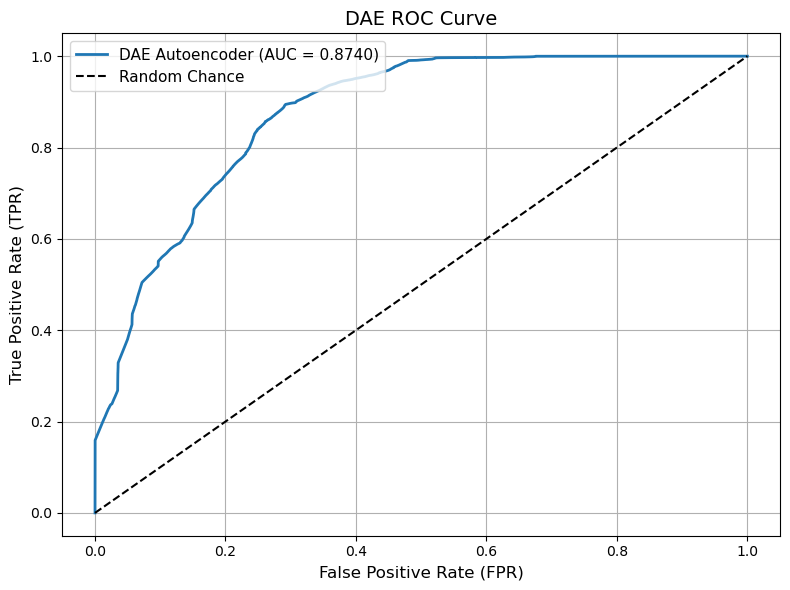

In [300]:

# 1. Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
# We use dae_scores because ROC curves require continuous scores/probabilities, not binary predictions.
fpr, tpr, thresholds = roc_curve(y_test_flat, dae_scores)
auc_score = roc_auc_score(y_test_flat, dae_scores)

# 2. Plotting configuration to match your image
plt.figure(figsize=(8, 6))

# Plot the DAE ROC curve
plt.plot(fpr, tpr, label=f'DAE Autoencoder (AUC = {auc_score:.4f})', color='tab:blue', linewidth=2)

# Plot the Random Chance diagonal line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random Chance')

# 3. Graph formatting (Labels, Title, Grid, Legend)
plt.title('DAE ROC Curve', fontsize=14)
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend(loc='upper left', fontsize=11)

# 4. Display or Save the plot
plt.tight_layout()
plt.show()
# If running headless or on a remote server, uncomment the line below to save it instead:
# plt.savefig('dae_roc_curve.png', dpi=300)

--- Training VQ-VAE ---
Epoch 1/30 Train Loss: 219060684.6833 Val Loss: 4299391849948.6216
Epoch 2/30 Train Loss: 218231779.2800 Val Loss: 4292438071974.9272
Epoch 3/30 Train Loss: 217479603.1568 Val Loss: 4285603988854.4600
Epoch 4/30 Train Loss: 216740163.9331 Val Loss: 4278813455463.0591
Epoch 5/30 Train Loss: 216010153.4782 Val Loss: 4272053793383.1792
Epoch 6/30 Train Loss: 215288429.3019 Val Loss: 4265320416145.8335
Epoch 7/30 Train Loss: 214574091.0314 Val Loss: 4258609975691.9731
Epoch 8/30 Train Loss: 213866281.6932 Val Loss: 4251920066216.9648
Epoch 9/30 Train Loss: 213164383.8517 Val Loss: 4245248450200.2100
Epoch 10/30 Train Loss: 212467776.1427 Val Loss: 4238594777335.1792
Epoch 11/30 Train Loss: 211776003.2892 Val Loss: 4231958584404.6382
Epoch 12/30 Train Loss: 211088810.1504 Val Loss: 4225340920500.7578
Epoch 13/30 Train Loss: 210405790.1057 Val Loss: 4218742112168.4614
Epoch 14/30 Train Loss: 209726974.5006 Val Loss: 4212162759976.1499
Epoch 15/30 Train Loss: 209052216

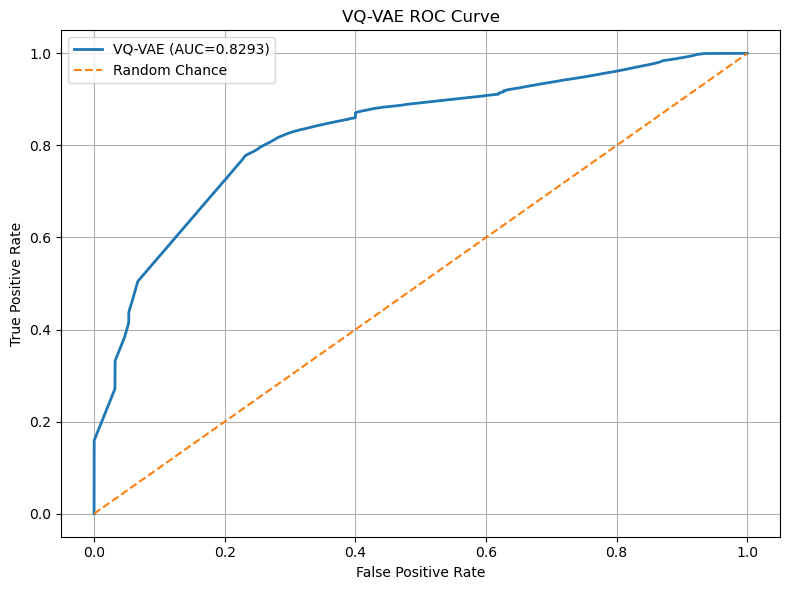

In [301]:
num_features = train_X.shape[1] 

flat_labels = test_Y.cpu().numpy().flatten()
# Execution routines
model = VQVAE(input_dim=num_features)
model = VQVAE(input_dim=num_features)

test_scores, preds, threshold, auc = train_and_test_vqvae(model, train_loader, val_loader, loader, val_Y_numpy, flat_labels, num_features, epochs=30
)

In [302]:
# Extract parameters from your active workspace arrays
num_features = train_X.shape[1] 

GAE_Model = GraphAutoencoder(num_features)
# Execution routines
train_and_test_gae(GAE_Model, train_loader, val_loader, loader, val_Y_numpy, flat_labels, num_features, epochs=30)

--- Training Graph Autoencoder ---
Epoch 1/30, Loss: 18.6554
Epoch 2/30, Loss: 4.7271
Epoch 3/30, Loss: 2.8321
Epoch 4/30, Loss: 3.5788
Epoch 5/30, Loss: 2.0395
Epoch 6/30, Loss: 1.1443
Epoch 7/30, Loss: 0.7192
Epoch 8/30, Loss: 0.7029
Epoch 9/30, Loss: 0.7029
Epoch 10/30, Loss: 0.7036
Epoch 11/30, Loss: 0.7080
Epoch 12/30, Loss: 0.7167
Epoch 13/30, Loss: 0.7027
Epoch 14/30, Loss: 0.7055
Epoch 15/30, Loss: 0.7054
Epoch 16/30, Loss: 0.7078
Epoch 17/30, Loss: 0.7041
Epoch 18/30, Loss: 0.7236
Epoch 19/30, Loss: 0.7030
Epoch 20/30, Loss: 0.7021
Epoch 21/30, Loss: 0.7063
Epoch 22/30, Loss: 0.7042
Epoch 23/30, Loss: 0.7028
Epoch 24/30, Loss: 0.7017
Epoch 25/30, Loss: 0.7204
Epoch 26/30, Loss: 0.7014
Epoch 27/30, Loss: 0.7037
Epoch 28/30, Loss: 0.7059
Epoch 29/30, Loss: 0.7053
Epoch 30/30, Loss: 0.7110
Execution Time: 2.5847284580231644
Best Threshold: 127.562421
Validation F1: 0.7727
Execution Time: 3.9767877500271425
Execution Time (Test specific,confirmed): 4.0013678749674
GAE ROC-AUC: 0.2

(array([128.54315, 128.54315, 128.54315, ..., 102.66979, 102.66979,
        102.66979], dtype=float32),
 array([1, 1, 1, ..., 0, 0, 0]),
 127.56242129033457,
 0.2882179033474118)

In [ ]:
rnn_model = AERNN(46572, train_X.shape[1], 256 , 8)

optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [ ]:
rnn_model = AERNN(seq_len=1, n_features=train_X.shape[1], latent_dim=256, hidden_size=8)

optimizer = torch.optim.Adam(rnn_model.parameters(), lr=5e-3)
loss_fn = nn.MSELoss()

num_epochs = 30
print("Starting AERNN Training Loop...")

for epoch in range(num_epochs):
    rnn_model.train()
    train_loss = 0
    
    for batch in train_loader:
        x = batch[0] 
        
        x_seq = x.unsqueeze(1)
        
        optimizer.zero_grad()
        recon = rnn_model(x_seq)
        
        loss = loss_fn(recon, x_seq)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {train_loss / len(train_loader):.4f}")

Starting AERNN Training Loop...
Epoch 1/30, Avg Loss: 219206283.2639
Epoch 2/30, Avg Loss: 217931971.2956
Epoch 3/30, Avg Loss: 216677027.4542
Epoch 4/30, Avg Loss: 215438571.4484
Epoch 5/30, Avg Loss: 214679803.5782
Epoch 6/30, Avg Loss: 213798611.0460
Epoch 7/30, Avg Loss: 212733740.1597
Epoch 8/30, Avg Loss: 211685177.3826
Epoch 9/30, Avg Loss: 210649666.8104
Epoch 10/30, Avg Loss: 209626909.0573
Epoch 11/30, Avg Loss: 208616922.6809
Epoch 12/30, Avg Loss: 207619811.1943
Epoch 13/30, Avg Loss: 206635656.2236
Epoch 14/30, Avg Loss: 205664551.4785
Epoch 15/30, Avg Loss: 204706769.2332
Epoch 16/30, Avg Loss: 203762465.3804
Epoch 17/30, Avg Loss: 202832002.5333
Epoch 18/30, Avg Loss: 201915403.7693
Epoch 19/30, Avg Loss: 201012577.7637
Epoch 20/30, Avg Loss: 200123178.2335
Epoch 21/30, Avg Loss: 208070192.3558
Epoch 22/30, Avg Loss: 199043874.0220
Epoch 23/30, Avg Loss: 205387491.5902
Epoch 24/30, Avg Loss: 203493705.7517
Epoch 25/30, Avg Loss: 202808148.9717
Epoch 26/30, Avg Loss: 2021

In [306]:
train_X

tensor([[3.3000e+01, 5.0000e+01, 1.9000e+01,  ..., 2.9412e-02, 0.0000e+00,
         0.0000e+00],
        [2.0000e+00, 2.0000e+01, 1.0000e+00,  ..., 0.0000e+00, 0.0000e+00,
         0.0000e+00],
        [2.0000e+00, 2.0000e+01, 1.0000e+00,  ..., 0.0000e+00, 0.0000e+00,
         1.0000e+00],
        ...,
        [5.0000e+01, 3.3000e+01, 2.9000e+01,  ..., 2.9412e-02, 0.0000e+00,
         2.7302e+04],
        [7.9800e+02, 1.4080e+03, 2.6000e+01,  ..., 0.0000e+00, 0.0000e+00,
         2.5495e+04],
        [5.0000e+01, 3.3000e+01, 2.9000e+01,  ..., 2.9412e-02, 0.0000e+00,
         2.7303e+04]])

In [307]:
def get_rnn_scores(model, loader, device):

    model.eval()

    scores = []

    with torch.no_grad():
        start_time = time.perf_counter()
        for batch in loader:

            x = batch[0].to(device)

            # Add sequence dimension
            x_seq = x.unsqueeze(1)

            recon = model(x_seq)

            # Reconstruction error per sample
            loss = F.mse_loss(
                recon,
                x_seq,
                reduction="none"
            ).sum(dim=-1).squeeze(-1)


            scores.extend(
                loss.cpu().numpy()
            )

    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    return np.asarray(scores)



# ==========================================
# Generate validation scores
# ==========================================

val_anomaly_scores = get_rnn_scores(
    rnn_model,
    val_loader,
    device
)


# Convert validation labels
if hasattr(val_Y, "cpu"):
    val_labels = val_Y.cpu().numpy().ravel().astype(int)
else:
    val_labels = np.asarray(val_Y).ravel().astype(int)



# ==========================================
# Find optimal threshold using validation set
# ==========================================

best_threshold = None
best_f1 = -1


thresholds = np.linspace(
    val_anomaly_scores.min(),
    val_anomaly_scores.max(),
    500
)


for threshold in thresholds:

    val_preds = (
        val_anomaly_scores >= threshold
    ).astype(int)


    score = f1_score(
        val_labels,
        val_preds,
        zero_division=0
    )


    if score > best_f1:
        best_f1 = score
        best_threshold = threshold



print(
    f"Best Validation Threshold: {best_threshold:.6f}"
)

print(
    f"Best Validation F1: {best_f1:.4f}"
)



# ==========================================
# Evaluate on Test Set
# ==========================================

test_anomaly_scores = get_rnn_scores(
    rnn_model,
    eval_loader,
    device
)


# Convert test labels
if hasattr(test_Y, "cpu"):
    test_labels = test_Y.cpu().numpy().ravel().astype(int)
else:
    test_labels = np.asarray(test_Y).ravel().astype(int)



# Apply frozen threshold
test_predictions = (
    test_anomaly_scores >= best_threshold
).astype(int)



# ==========================================
# Final Metrics
# ==========================================

auc = roc_auc_score(
    test_labels,
    test_anomaly_scores
)


print("\n--- AERNN Results ---")

print(
    f"ROC-AUC: {auc:.4f}"
)


print(
    classification_report(
        test_labels,
        test_predictions,
        zero_division=0
    )
)


print(
    f"Mean Reconstruction Error: {test_anomaly_scores.mean():.6f}"
)


Execution Time: 2.8447828339994885
Best Validation Threshold: 81983768.417836
Best Validation F1: 0.9128
Execution Time: 4.735399374971166

--- AERNN Results ---
ROC-AUC: 0.8303
              precision    recall  f1-score   support

           0       0.75      0.65      0.69    472571
           1       0.77      0.85      0.81    666015

    accuracy                           0.76   1138586
   macro avg       0.76      0.75      0.75   1138586
weighted avg       0.76      0.76      0.76   1138586

Mean Reconstruction Error: 6097291776.000000


In [308]:
# --- Update your dataset definitions ---
# Include both the features (data_X) and ground truth labels (data_Y)
# Change this line:
# data_Y = torch.tensor(data_y.values, dtype=torch.float32)

# # To this (flattens the 2D column into a clean 1D array):
# data_Y = torch.tensor(data_y.values, dtype=torch.float32).squeeze()
# eval_dataset = TensorDataset(data_X, data_Y)

# # Re-create your evaluation loader using the updated dataset
# eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)

In [ ]:
# import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
import torch

def plot_loss_moment(losses):
    if not losses:
        print("No losses to plot.")
        return
    fig, ax = plt.subplots(figsize=(16, 9), dpi=80)
    ax.plot(losses, 'blue', label='train', linewidth=1)
    ax.set_title('Loss change in training')
    ax.set_ylabel('Loss')
    ax.set_xlabel('Iteration')
    ax.legend(loc='upper right')

    plt.close(fig)

compressor = CompressNet(train_X.shape[1], 256, 128, 64, 32)
estimator = EstimateNet(34, 512, hyper_params.dropout_p, 2, hyper_params.lam1, hyper_params.lam2)

losses = []
loss_plot_interval = 20
steps = 0
loss_total = 0

compressor_opt = torch.optim.Adam(compressor.parameters(), lr=1e-3, amsgrad=True)
estimator_opt = torch.optim.Adam(estimator.parameters(), lr=1e-3, amsgrad=True)

print("Starting training debug run...")

for i in range(hyper_params.epoch_num):
    for batch in train_loader: 
        x = batch[0]  
        steps += 1

        z, x_hat = compressor(x)
        loss = compressor.reconstruct_error(x, x_hat)

        gamma = estimator(z)
        loss += estimator.energy(gamma, z)
        loss_total += loss.detach().item()

        compressor_opt.zero_grad()
        estimator_opt.zero_grad()

        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(compressor.parameters(), max_norm=5.0)
        torch.nn.utils.clip_grad_norm_(estimator.parameters(), max_norm=5.0)
        
        compressor_opt.step()
        estimator_opt.step()

        if steps % loss_plot_interval == 0:
            print(f'Epoch: {i}  step: {steps}  loss: {loss_total/loss_plot_interval:.4f}')
            losses.append(loss_total / loss_plot_interval)
            loss_total = 0

Starting training debug run...
Epoch: 0  step: 20  loss: 1595.1220
Epoch: 0  step: 40  loss: 1819.6052
Epoch: 0  step: 60  loss: 2344.9451
Epoch: 0  step: 80  loss: 2642.9500
Epoch: 0  step: 100  loss: 3089.6459
Epoch: 0  step: 120  loss: 4047.5187
Epoch: 0  step: 140  loss: 3530.5101
Epoch: 0  step: 160  loss: 3646.4568
Epoch: 0  step: 180  loss: 4332.9420
Epoch: 0  step: 200  loss: 4738.8238
Epoch: 0  step: 220  loss: 4852.0431
Epoch: 0  step: 240  loss: 6113.4037
Epoch: 0  step: 260  loss: 6142.6993
Epoch: 0  step: 280  loss: 6321.0246
Epoch: 0  step: 300  loss: 6734.3750
Epoch: 0  step: 320  loss: 6693.7991
Epoch: 0  step: 340  loss: 7425.0087
Epoch: 0  step: 360  loss: 8037.0036
Epoch: 0  step: 380  loss: 8951.2295
Epoch: 0  step: 400  loss: 8571.0602
Epoch: 0  step: 420  loss: 9077.0502
Epoch: 0  step: 440  loss: 9049.1817
Epoch: 0  step: 460  loss: 10803.4207
Epoch: 0  step: 480  loss: 11356.4796
Epoch: 0  step: 500  loss: 11479.7061
Epoch: 0  step: 520  loss: 12011.1212
Epoch: 

In [ ]:

compressor.eval()
estimator.eval()

all_scores = []


with torch.no_grad():

    for batch in eval_loader:

        x = batch[0].to(device)


        z, _ = compressor(x)


        gamma = estimator(z)

        m_prob = estimator.mixture_prob(gamma)
        m_mean = estimator.mixture_mean(gamma, z)
        m_cov = estimator.mixture_covar(
            gamma,
            z,
            m_mean
        )


        N, D = z.shape


        log_energies = torch.zeros(
            (N, estimator.mixture_dim),
            device=z.device
        )


        for k in range(estimator.mixture_dim):

            _, logdet = torch.linalg.slogdet(
                m_cov[k]
            )


            inv_cov = torch.linalg.pinv(
                m_cov[k]
            )


            diff = z - m_mean[k]

            mahalanobis = torch.sum(
                torch.matmul(diff, inv_cov) * diff,
                dim=1
            )


            log_density = -0.5 * (
                D * np.log(2 * np.pi)
                + logdet
                + mahalanobis
            )


            log_energies[:, k] = (
                torch.log(
                    m_prob[k] + 1e-8
                )
                + log_density
            )


        batch_scores = (
            -torch.logsumexp(
                log_energies,
                dim=1
            )
            .cpu()
            .numpy()
        )


        all_scores.append(batch_scores)



final_scores = np.concatenate(all_scores)




if hasattr(test_Y, "cpu"):

    final_labels = (
        test_Y
        .cpu()
        .numpy()
        .flatten()
        .astype(int)
    )

else:

    final_labels = (
        np.asarray(test_Y)
        .flatten()
        .astype(int)
    )




final_preds = (
    final_scores >= threshold
).astype(int)



print("================ DAGMM RESULTS ================")


print(
    "Label Distribution:",
    np.unique(
        final_labels,
        return_counts=True
    )
)


print(
    "Prediction Distribution:",
    np.unique(
        final_preds,
        return_counts=True
    )
)


print("\nClassification Report:")
print(
    classification_report(
        final_labels,
        final_preds,
        zero_division=0
    )
)


auc = roc_auc_score(
    final_labels,
    final_scores
)


print(
    f"\nROC-AUC Score: {auc:.4f}"
)


print(
    f"Mean Energy Score: {final_scores.mean():.6f}")

================ DAGMM RESULTS ================
Label Distribution: (array([0, 1]), array([472571, 666015]))
Prediction Distribution: (array([0]), array([1138586]))

Classification Report:
              precision    recall  f1-score   support

           0       0.42      1.00      0.59    472571
           1       0.00      0.00      0.00    666015

    accuracy                           0.42   1138586
   macro avg       0.21      0.50      0.29   1138586
weighted avg       0.17      0.42      0.24   1138586


ROC-AUC Score: 0.1497
Mean Energy Score: -76.993248


In [311]:
all_labels = []
for batch in loader:
    if len(batch) > 1:
        all_labels.extend(batch[1].cpu().numpy())
    else:
        all_labels.extend(np.zeros(batch[0].size(0)))

unique, counts = np.unique(all_labels, return_counts=True)
print("Label distribution in evaluation loader:")
print(dict(zip(unique, counts)))

Label distribution in evaluation loader:
{0.0: 1138586}


In [312]:
nz = 100 # Size of the latent noise vector

generator_model = Generator(input_dim=nz, hidden_dim=128, output_dim=train_X.shape[1])
discriminator_model = Discriminator(input_dim=train_X.shape[1], hidden_dim=128)

# Re-setup Adam optimizers to point to the new parameters
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))


In [313]:
# Initialize the ``BCELoss`` function
criterion = nn.BCELoss()

# Create batch of latent vectors that we will use to visualize
#  the progression of the generator
# fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.
lr = 0.0001

# Setup Adam optimizers for both G and D
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=lr)
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=lr)

In [314]:
nz = 100


In [315]:
import torch
import torch.nn as nn


def train_gan_anomaly_detector(
    netG,
    netD,
    train_loader,
    epochs,
    device,
    latent_dim=100
):

    netG = netG.to(device)
    netD = netD.to(device)


    criterion = nn.BCELoss()


    optimizerD = torch.optim.Adam(
        netD.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )


    optimizerG = torch.optim.Adam(
        netG.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )


    G_losses = []
    D_losses = []


    print("Starting GAN anomaly detection training...")


    for epoch in range(epochs):

        for batch in train_loader:

            # ================================
            # Real normal samples
            # ================================

            real = batch[0].to(device)

            batch_size = real.size(0)


            real_labels = torch.ones(
                batch_size,
                device=device
            )

            fake_labels = torch.zeros(
                batch_size,
                device=device
            )


            # ================================
            # Train Discriminator
            # ================================

            netD.zero_grad()


            # Real normal traffic
            output_real = netD(real).view(-1)


            loss_real = criterion(
                output_real,
                real_labels
            )


            # Generate fake normal-like traffic
            noise = torch.randn(
                batch_size,
                latent_dim,
                device=device
            )


            fake = netG(noise)


            output_fake = netD(
                fake.detach()
            ).view(-1)


            loss_fake = criterion(
                output_fake,
                fake_labels
            )


            loss_D = loss_real + loss_fake


            loss_D.backward()

            optimizerD.step()



            # ================================
            # Train Generator
            # ================================

            netG.zero_grad()


            output_fake = netD(fake).view(-1)


            # Generator wants discriminator
            # to classify generated samples as real

            loss_G = criterion(
                output_fake,
                real_labels
            )


            loss_G.backward()

            optimizerG.step()



            G_losses.append(
                loss_G.item()
            )

            D_losses.append(
                loss_D.item()
            )


        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"D Loss: {loss_D.item():.4f} "
            f"G Loss: {loss_G.item():.4f}"
        )


    return netG, netD, G_losses, D_losses

In [316]:
netD = Discriminator(input_dim=8)
netG = Generator(100,hidden_dim=256,output_dim=8)

In [317]:
netG, netD, G_losses, D_losses = train_gan_anomaly_detector(
    netG,
    netD,
    train_loader,
    epochs=50,
    device=device,
    latent_dim=100
)

Starting GAN anomaly detection training...
Epoch [1/50] D Loss: 0.0021 G Loss: 6.1584
Epoch [2/50] D Loss: 0.0003 G Loss: 8.0666
Epoch [3/50] D Loss: 0.0001 G Loss: 9.4330
Epoch [4/50] D Loss: 0.0000 G Loss: 10.8040
Epoch [5/50] D Loss: 0.0000 G Loss: 11.9892
Epoch [6/50] D Loss: 0.0000 G Loss: 12.9669
Epoch [7/50] D Loss: 0.0000 G Loss: 13.6042
Epoch [8/50] D Loss: 0.0000 G Loss: 14.6011
Epoch [9/50] D Loss: 0.0000 G Loss: 15.3305
Epoch [10/50] D Loss: 0.0000 G Loss: 14.6283
Epoch [11/50] D Loss: 0.0000 G Loss: 15.7226
Epoch [12/50] D Loss: 0.0000 G Loss: 13.2412
Epoch [13/50] D Loss: 0.0000 G Loss: 14.1719
Epoch [14/50] D Loss: 0.0000 G Loss: 14.6489
Epoch [15/50] D Loss: 0.0000 G Loss: 15.1277
Epoch [16/50] D Loss: 0.0000 G Loss: 14.8454
Epoch [17/50] D Loss: 0.0000 G Loss: 15.7780
Epoch [18/50] D Loss: 0.0000 G Loss: 16.8605
Epoch [19/50] D Loss: 0.0000 G Loss: 18.2677
Epoch [20/50] D Loss: 0.0000 G Loss: 19.1566
Epoch [21/50] D Loss: 0.0000 G Loss: 20.2863
Epoch [22/50] D Loss: 0.

In [318]:
import torch
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_fscore_support,
    classification_report,
    f1_score
)


def get_anomaly_scores(discriminator_model, loader, device="cpu"):
    """
    Generates anomaly scores from discriminator.
    
    Assumption:
        Discriminator output:
        High value = normal
        Low value = anomaly
        
    Therefore:
        anomaly_score = 1 - discriminator_output
    """

    discriminator_model.eval()

    scores = []

    with torch.no_grad():

        for batch in loader:

            x = batch[0].to(device)

            outputs = discriminator_model(x).view(-1)

            # Convert normal probability into anomaly score
            anomaly_scores = 1.0 - outputs

            scores.extend(
                anomaly_scores.cpu().numpy()
            )

    return np.asarray(scores)



def find_best_threshold(scores, labels):
    """
    Finds threshold using validation data only.
    """

    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        scores.min(),
        scores.max(),
        500
    )


    for threshold in thresholds:

        predictions = (
            scores >= threshold
        ).astype(int)


        f1 = f1_score(
            labels,
            predictions,
            zero_division=0
        )


        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold


    return best_threshold, best_f1



def evaluate_anomaly_detector(
    discriminator_model,
    val_loader,
    val_Y,
    test_loader,
    test_Y,
    device="cpu"
):

    discriminator_model = discriminator_model.to(device)


    # ==========================================
    # Validation Phase (Threshold Selection)
    # ==========================================

    val_scores = get_anomaly_scores(
        discriminator_model,
        val_loader,
        device
    )


    if hasattr(val_Y, "cpu"):
        val_labels = (
            val_Y.cpu()
            .numpy()
            .flatten()
            .astype(int)
        )
    else:
        val_labels = (
            np.asarray(val_Y)
            .flatten()
            .astype(int)
        )


    threshold, val_f1 = find_best_threshold(
        val_scores,
        val_labels
    )


    print(
        f"Best Validation Threshold: {threshold:.6f}"
    )

    print(
        f"Validation F1: {val_f1:.4f}"
    )



    # ==========================================
    # Test Phase
    # ==========================================

    test_scores = get_anomaly_scores(
        discriminator_model,
        test_loader,
        device
    )


    if hasattr(test_Y, "cpu"):
        test_labels = (
            test_Y.cpu()
            .numpy()
            .flatten()
            .astype(int)
        )
    else:
        test_labels = (
            np.asarray(test_Y)
            .flatten()
            .astype(int)
        )


    # Apply validation threshold
    predictions = (
        test_scores >= threshold
    ).astype(int)



    # ==========================================
    # Metrics
    # ==========================================

    auc_score = roc_auc_score(
        test_labels,
        test_scores
    )


    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            test_labels,
            predictions,
            average="binary",
            zero_division=0
        )
    )


    print("\n=== Semi-Supervised Evaluation Results ===")

    print(
        f"ROC-AUC Score: {auc_score:.4f}"
    )

    print(
        f"Precision: {precision:.4f}"
    )

    print(
        f"Recall:    {recall:.4f}"
    )

    print(
        f"F1-Score:  {f1:.4f}"
    )


    print("\nClassification Report:")
    print(
        classification_report(
            test_labels,
            predictions,
            target_names=[
                "Normal",
                "Anomaly"
            ],
            zero_division=0
        )
    )


    return {
        "auc": auc_score,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "threshold": threshold,
        "scores": test_scores,
        "labels": test_labels
    }

In [319]:
# X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
# y_test_tensor = torch.tensor(y_test, dtype=torch.long)  # Or float32 depending on loss, long is standard for labels
# test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# # 3. Re-run your loader creation from before
# test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [320]:
# 3. Pass THIS new loader into your evaluation function
results = evaluate_anomaly_detector(discriminator_model,val_loader,val_Y, eval_loader,test_Y, device="cpu")

Best Validation Threshold: 1.000000
Validation F1: 0.7752

=== Semi-Supervised Evaluation Results ===
ROC-AUC Score: 0.5011
Precision: 0.5855
Recall:    0.9960
F1-Score:  0.7374

Classification Report:
              precision    recall  f1-score   support

      Normal       0.52      0.01      0.01    472571
     Anomaly       0.59      1.00      0.74    666015

    accuracy                           0.59   1138586
   macro avg       0.55      0.50      0.37   1138586
weighted avg       0.56      0.59      0.44   1138586



In [321]:
# Assuming your test data loader returns (features, true_labels)
# where true_labels uses 0 for normal and 1 for attacks
# from torch.utils.data import DataLoader

# # Create the test_loader (adjust batch_size to match your training configuration)
# # test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

# # Now run the evaluation function
# # results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

# results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

In [322]:
import sklearn.svm
from sklearn.linear_model import SGDOneClassSVM
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,f1_score,classification_report

# train_X, test_X, train_Y, test_Y = train_test_split(data_X.numpy(),data_Y.numpy(),test_size=0.2)

scaler = StandardScaler()
train_x_values = scaler.fit_transform(train_X)
test_x_values = scaler.transform(test_X)
val_x_values = scaler.transform(val_X)

model = SGDOneClassSVM(
    nu=0.05,
    random_state=42
)
print(train_X)
print()
model.fit(train_x_values)
val_scores = -model.decision_function(val_x_values)

start_time = time.perf_counter()
predictions = -model.decision_function(test_x_values)
predictions
# f1_score(test_Y,predictions)
mapped_predictions = np.where(predictions == -1, 1, 0)

# Now evaluate safely
# from sklearn.metrics import classification_report

print(classification_report(test_Y, mapped_predictions))
print("\nAUC Score:\n",roc_auc_score(test_Y, predictions))
end_time = time.perf_counter()
print(f"Execution Time: {end_time-start_time}")


tensor([[3.3000e+01, 5.0000e+01, 1.9000e+01,  ..., 2.9412e-02, 0.0000e+00,
         0.0000e+00],
        [2.0000e+00, 2.0000e+01, 1.0000e+00,  ..., 0.0000e+00, 0.0000e+00,
         0.0000e+00],
        [2.0000e+00, 2.0000e+01, 1.0000e+00,  ..., 0.0000e+00, 0.0000e+00,
         1.0000e+00],
        ...,
        [5.0000e+01, 3.3000e+01, 2.9000e+01,  ..., 2.9412e-02, 0.0000e+00,
         2.7302e+04],
        [7.9800e+02, 1.4080e+03, 2.6000e+01,  ..., 0.0000e+00, 0.0000e+00,
         2.5495e+04],
        [5.0000e+01, 3.3000e+01, 2.9000e+01,  ..., 2.9412e-02, 0.0000e+00,
         2.7303e+04]])



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples

              precision    recall  f1-score   support

         0.0       0.42      1.00      0.59    472571
         1.0       0.00      0.00      0.00    666015

    accuracy                           0.42   1138586
   macro avg       0.21      0.50      0.29   1138586
weighted avg       0.17      0.42      0.24   1138586


AUC Score:
 0.38097724444939596
Execution Time: 0.8319404579815455
